# Explore ASHP upfront cost predictions from revived quantile regression model
Ryan Treves

### Setup

In [0]:
%load_ext autoreload
%autoreload 2

In [0]:
# Manually setting poetry version because we're at a shallower dir depth than expected by the util function
CURRENT_POETRY_VERISON = "1_1_0"

### Imports

In [0]:
import pandas as pd
import numpy as np
import pyspark.sql.functions as F
from mlflow.tracking import MlflowClient
import mlflow
import matplotlib.pyplot as plt
import seaborn as sns

from src import util, modeling_util

Exception ignored on calling ctypes callback function: <function _ThreadpoolInfo._find_modules_with_dl_iterate_phdr.<locals>.match_module_callback at 0x767493f3ede0>
Traceback (most recent call last):
  File "/databricks/python/lib/python3.11/site-packages/threadpoolctl.py", line 400, in match_module_callback
    self._make_module_from_path(filepath)
  File "/databricks/python/lib/python3.11/site-packages/threadpoolctl.py", line 515, in _make_module_from_path
    module = module_class(filepath, prefix, user_api, internal_api)
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/databricks/python/lib/python3.11/site-packages/threadpoolctl.py", line 606, in __init__
    self.version = self.get_version()
                   ^^^^^^^^^^^^^^^^^^
  File "/databricks/python/lib/python3.11/site-packages/threadpoolctl.py", line 646, in get_version
    config = get_config().split()
             ^^^^^^^^^^^^^^^^^^
AttributeError: 'NoneType' object has no attribute 'split'


### Load assets

In [0]:
# ResStock Predictions
predictions = spark.table("test.ashp_upfront_cost_by_building_1_1_0_ryan_revive_quantile_regression")
# Training data
# NOTE: was saved before I updated our version to 1_1_0
training_data = spark.table(util.modify_db_table_name(f"upfront_cost.hvac_training_features_1_0_0", mode="feature"))

test.hvac_training_features_1_0_0_ryan_revive_quantile_regression


In [0]:
# Convert to pandas
training_data_pd = training_data.toPandas()

In [0]:
# Load model based on Run ID
run_id = "dc5b6905e98e4cdc937b6f1684f10120"
model_uri = f"runs:/{run_id}/model"
loaded_model = mlflow.sklearn.load_model(model_uri)

In [0]:
# Identify which columns will be used for prediction
columns_for_prediction = [
    "heating_capacity_tons",
    "sqft",
    "seer",
    "hspf_region_iv",
    "had_duct_replacement",
    "had_panel_upgrade",
    "ducted",
]

### Analyze model coefficients

In [0]:
coefficients = pd.DataFrame(columns=columns_for_prediction)
for quantile in [0.2, 0.5, 0.8]:
    coefficients = pd.concat(
        [coefficients, pd.DataFrame(loaded_model.regressors_[quantile].coef_, index=columns_for_prediction).T],
        axis=0,
        ignore_index=True,
    )
coefficients.index = [0.2, 0.5, 0.8]
# Standardize for interpretability
for column in columns_for_prediction:
    coefficients[column] = coefficients[column] * (
        training_data_pd[column].std() / training_data_pd["project_cost_adjusted"].std()
    )
coefficients

,heating_capacity_tons,sqft,seer,hspf_region_iv,had_duct_replacement,had_panel_upgrade,ducted
0.2,0.465789,0.032196,-0.022552,-0.046577,0.094494,0.007010,-0.090426
0.5,0.603153,0.061408,-0.071489,-0.035530,0.122049,0.004383,-0.077636
0.8,0.708249,0.229986,-0.136242,0.016144,0.120478,0.040226,0.028955


I don't have 100% confidence in these interpretations, but they suggest that heating capacity is by far the most influential variable, followed by `had_duct_replacement` and `seer`.

### Predict on training data

In [0]:
# Convert several columns to numeric
columns_to_convert = ["project_cost_adjusted", "sqft"]
# Convert necessary columns to numeric
for column in columns_to_convert:
    training_data_pd[column] = pd.to_numeric(training_data_pd[column])

# Convert boolean features to numeric, they are currently stored as objects because of nan
training_data_pd["ducted"] = np.where(
    training_data_pd["ducted"] == True,  # noqa: E712
    1,
    np.where(training_data_pd["ducted"] == False, 0, np.nan),  # noqa: E712
)
training_data_pd["had_duct_replacement"] = np.where(
    training_data_pd["had_duct_replacement"] == True,  # noqa: E712
    1,
    np.where(training_data_pd["had_duct_replacement"] == False, 0, np.nan),  # noqa: E712
)
training_data_pd["had_panel_upgrade"] = np.where(
    training_data_pd["had_panel_upgrade"] == True,  # noqa: E712
    1,
    np.where(training_data_pd["had_panel_upgrade"] == False, 0, np.nan),  # noqa: E712
)

# filter out square footage and project costs that are considered to be outliers.
training_data_pd = training_data_pd[
    (training_data_pd["sqft"] > 100)
    & (training_data_pd["sqft"] <= 6000)
    & (training_data_pd["project_cost_adjusted"] <= 60000)
    & (training_data_pd["project_cost_adjusted"] > 0)
]

# Drop missing values
training_data_pd = training_data_pd.dropna(subset=columns_for_prediction, axis=0)

In [0]:
# Predict at preset quantiles
training_preds = (
    loaded_model.predict_quantiles(training_data_pd[columns_for_prediction], alpha=[0.2, 0.5, 0.8])
    .droplevel(0, axis=1)
    .rename(columns={0.2: "upfront_cost_20percentile", 0.5: "upfront_cost_median", 0.8: "upfront_cost_80percentile"})
)
training_preds = pd.concat([training_data_pd, training_preds], axis=1)

### Analyze training predictions

In [0]:
training_preds["program"].value_counts(dropna=False)

mass_ashp         19882
techclean_ca      16367
mass_wholehome       38
Name: program, dtype: int64

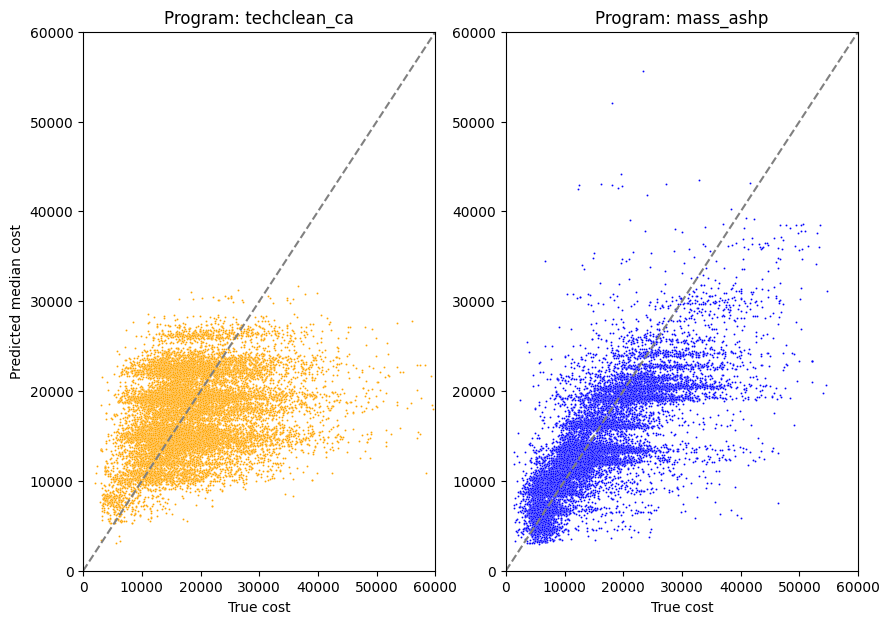

In [0]:
fig, ax = plt.subplots(1, 2, figsize=(10, 7))
for i, program in enumerate(["techclean_ca", "mass_ashp"]):
    sns.scatterplot(
        x="project_cost_adjusted",
        y="upfront_cost_median",
        data=training_preds[training_preds["program"] == program],
        s=2,
        ax=ax[i],
        color=["orange", "blue"][i],
        legend=False,
    )
    ax[i].set_title(f"Program: {program}")
ax[0].plot([0, 60000], [0, 60000], linestyle="--", color="gray")
ax[1].plot([0, 60000], [0, 60000], linestyle="--", color="gray")
ax[0].set_xlim(0, 60000)
ax[0].set_ylim(0, 60000)
ax[1].set_xlim(0, 60000)
ax[1].set_ylim(0, 60000)
ax[0].set_ylabel("Predicted median cost")
ax[1].set_ylabel("")
ax[0].set_xlabel("True cost")
ax[1].set_xlabel("True cost");

It appears the model produces a much tighter fit to the Mass ASHP data than the TechClean data.

In [0]:
# For what proportion of training examples does the true project cost fall within the predicted 20-80% quantile range?
(
    (training_preds["upfront_cost_20percentile"] < training_preds["project_cost_adjusted"])
    & (training_preds["upfront_cost_80percentile"] > training_preds["project_cost_adjusted"])
).value_counts(normalize=True)

True     0.602668
False    0.397332
dtype: float64

### Monotonicity

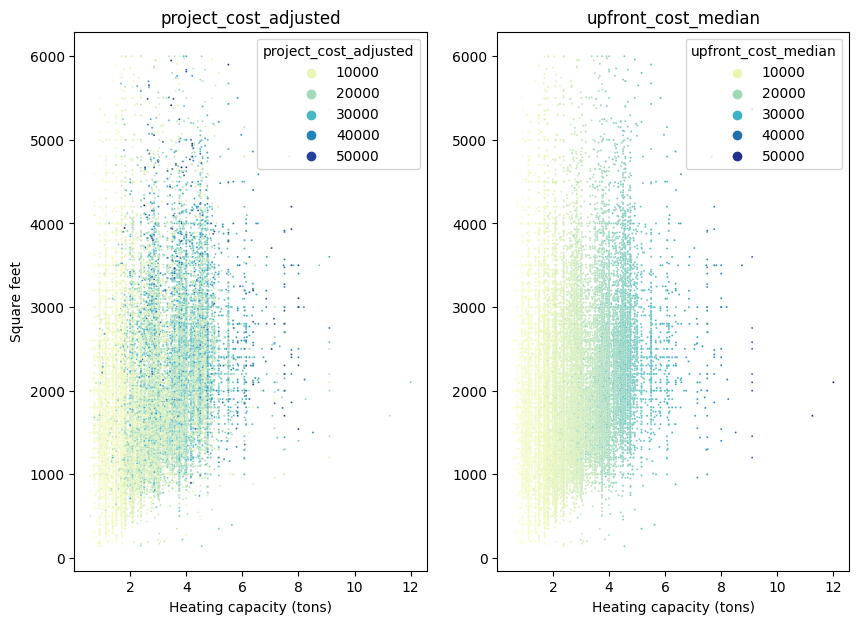

In [0]:
fig, ax = plt.subplots(1, 2, figsize=(10, 7))
for i, outcome in enumerate(["project_cost_adjusted", "upfront_cost_median"]):
    sns.scatterplot(
        x="heating_capacity_tons",
        y="sqft",
        data=training_preds,
        s=2,
        ax=ax[i],
        hue=outcome,
        palette="YlGnBu",
        legend=True,
    )
    ax[i].set_title(outcome)

ax[0].set_xlabel("Heating capacity (tons)")
ax[1].set_xlabel("Heating capacity (tons)")
ax[0].set_ylabel("Square feet")
ax[1].set_ylabel("");

We can see that the quantile regression model gives relatively monotonically increasing predictions with respect to heating capacity and square feet. Discrepancies are likely due to additional variables such as `seer` or `had_duct_replacement`.

### Explore ResStock-wide predictions

In [0]:
# Sample down predictions for efficiency
predictions_sampled = predictions.sample(fraction=0.01, seed=42)
predictions_sampled_pd = predictions_sampled.toPandas()

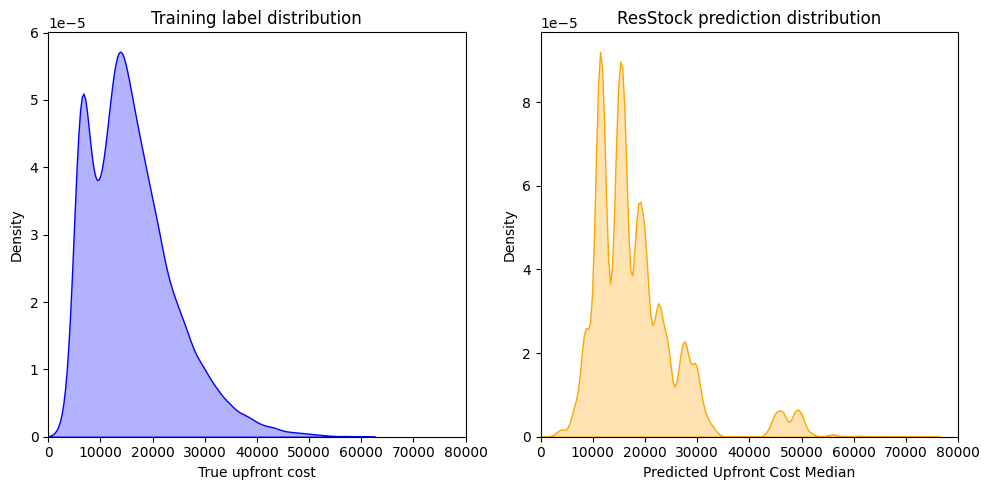

In [0]:
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
sns.kdeplot(data=training_preds, x="project_cost_adjusted", ax=ax[0], fill=True, color="blue", alpha=0.3)
ax[0].set_title("Training label distribution")
ax[0].set_xlabel("True upfront cost")
ax[0].set_xlim(0, 80000)

sns.kdeplot(data=predictions_sampled_pd, x="upfront_cost_median", ax=ax[1], fill=True, color="orange", alpha=0.3)
ax[1].set_title("ResStock prediction distribution")
ax[1].set_xlabel("Predicted Upfront Cost Median")
ax[1].set_xlim(0, 80000)

plt.tight_layout()

We see generally overlapping distributions of upfront cost in the training data and predicted upfront cost for ResStock, with the exception of a bump in high-cost predictions (~$50k).

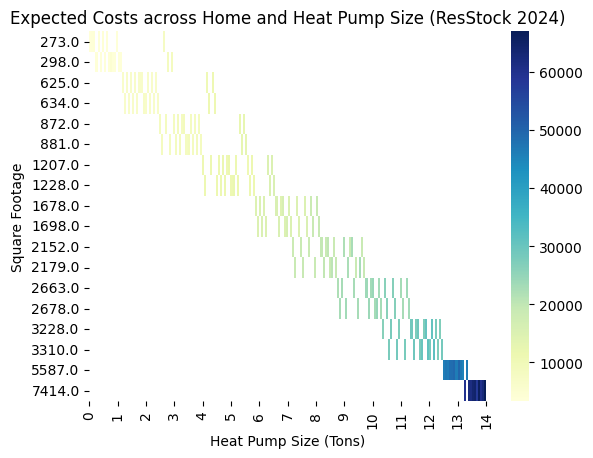

In [0]:
# Create a crosstab
ct = pd.crosstab(
    index=predictions_sampled_pd["sqft"],
    columns=predictions_sampled_pd["heating_capacity_tons"],
    values=predictions_sampled_pd["upfront_cost_median"],
    aggfunc="mean",
)

# Plot the crosstab as a heatmap
ax = sns.heatmap(ct, cmap="YlGnBu", annot=False)

# Number of columns in the heatmap
n_cols = ct.shape[1]

# Create 15 evenly spaced tick positions across the heatmap width
tick_positions = np.linspace(0, n_cols, 15)
tick_labels = [str(i) for i in range(15)]

# Apply them to the bottom axis
ax.set_xticks(tick_positions)
ax.set_xticklabels(tick_labels)

plt.title("Expected Costs across Home and Heat Pump Size (ResStock 2024)")
plt.ylabel("Square Footage")
plt.xlabel("Heat Pump Size (Tons)")
plt.show()

As expected, we see generally monotonicity w.r.t. heat pump size and sq footage.